Dataset Shape: (48120, 4)
              DateTime  Junction  Vehicles           ID
0  2015-11-01 00:00:00         1        15  20151101001
1  2015-11-01 01:00:00         1        13  20151101011
2  2015-11-01 02:00:00         1        10  20151101021
3  2015-11-01 03:00:00         1         7  20151101031
4  2015-11-01 04:00:00         1         9  20151101041
DateTime    0
Junction    0
Vehicles    0
ID          0
dtype: int64


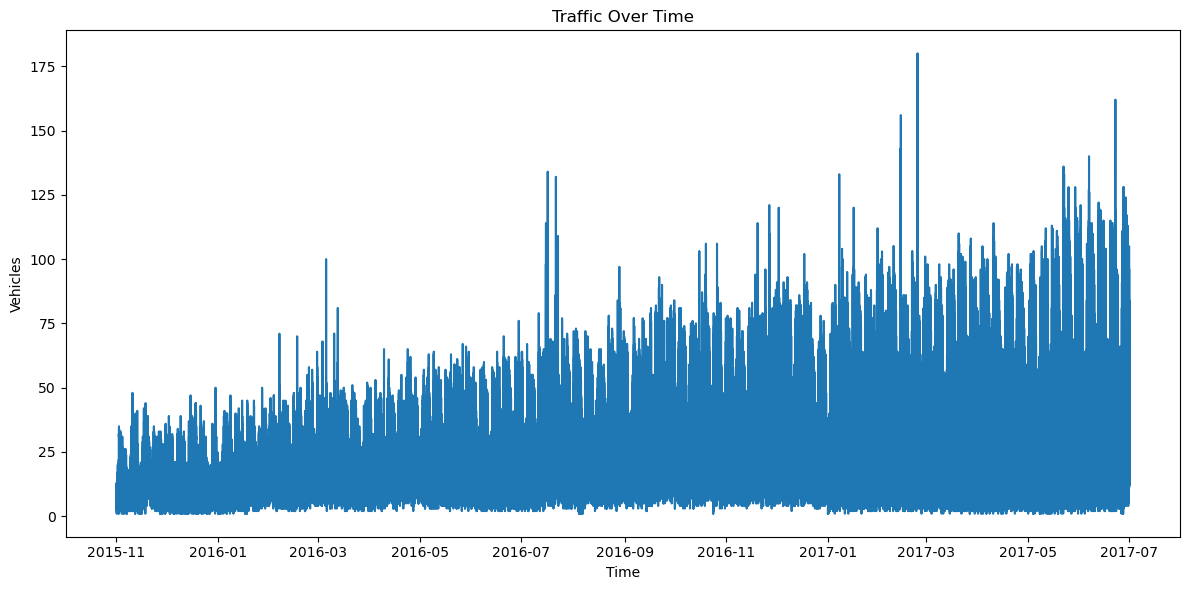

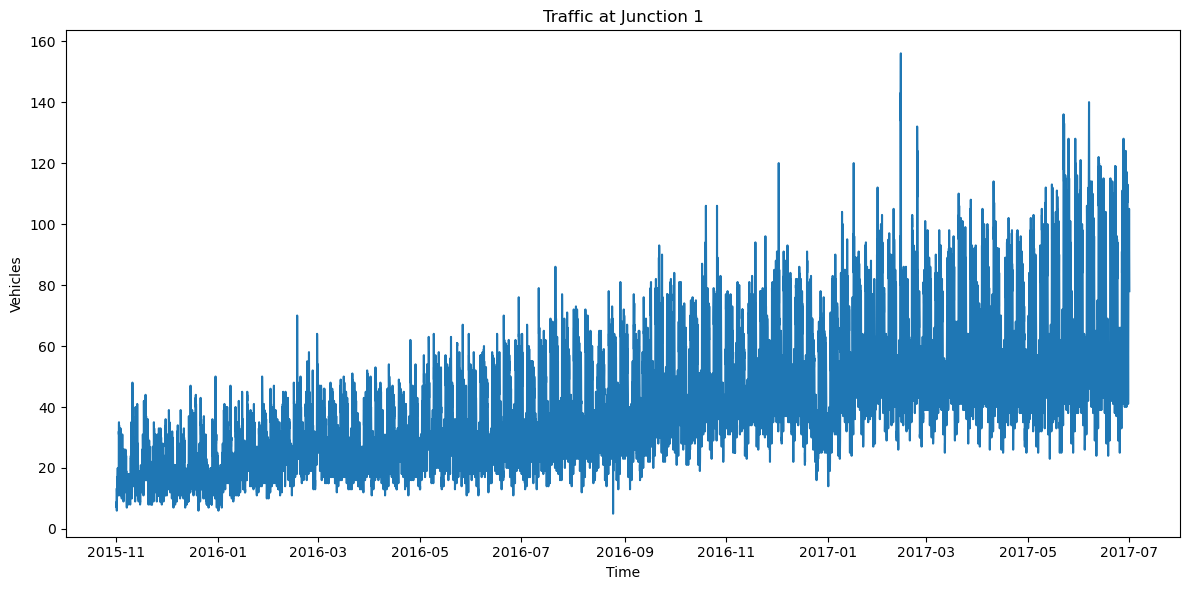

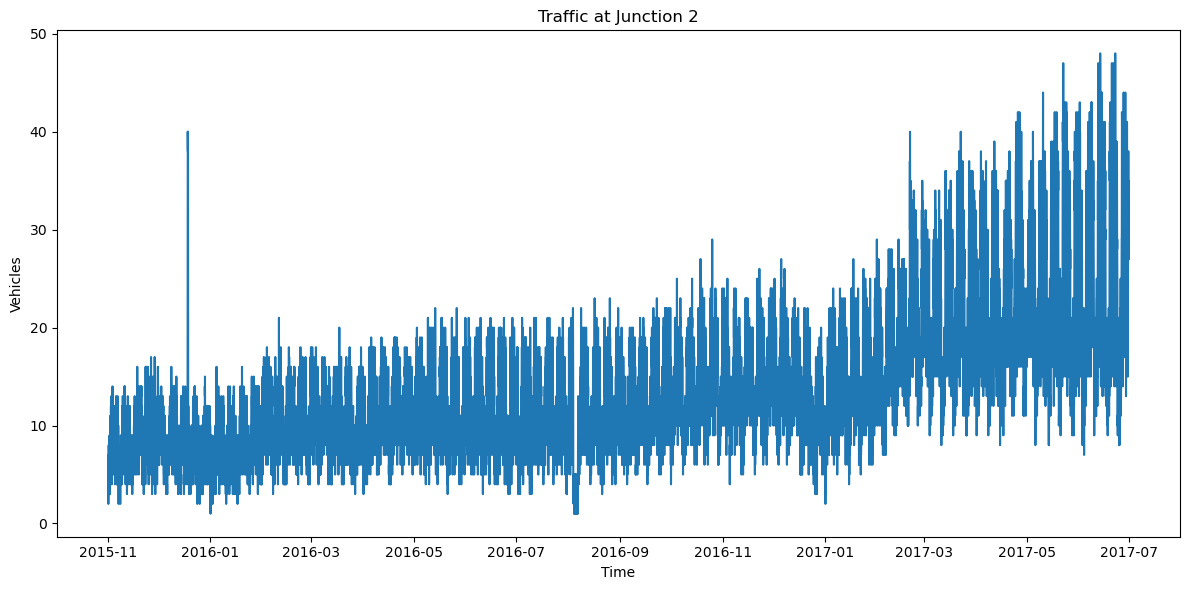

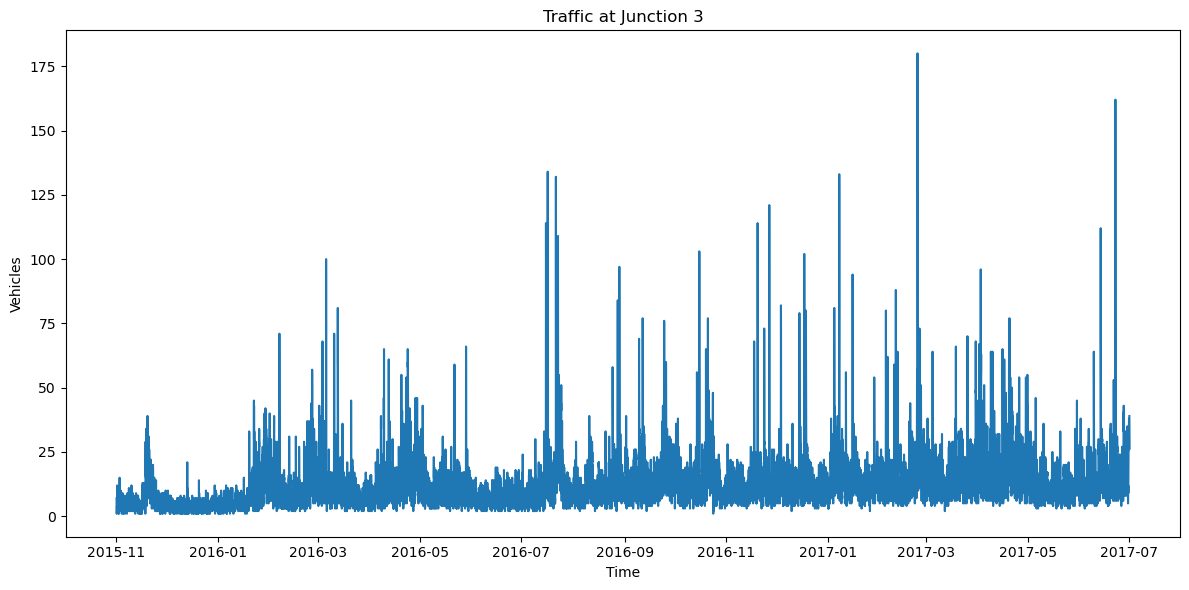

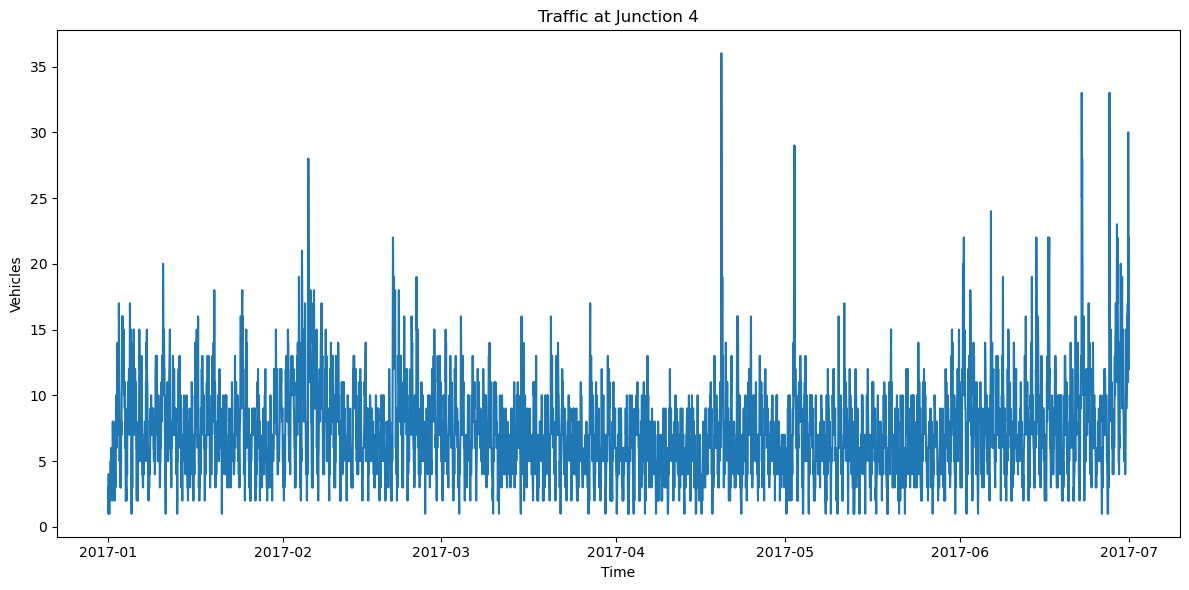

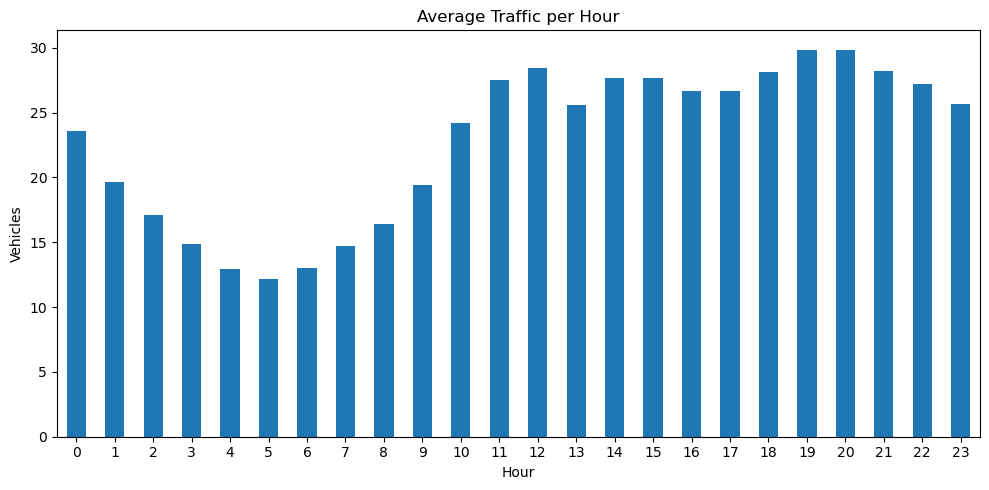


Linear Regression Performance:
MAE: 12.906121081795686
RMSE: 19.924042846501905

Random Forest Performance:
MAE: 10.306278342105543
RMSE: 16.84363313670558


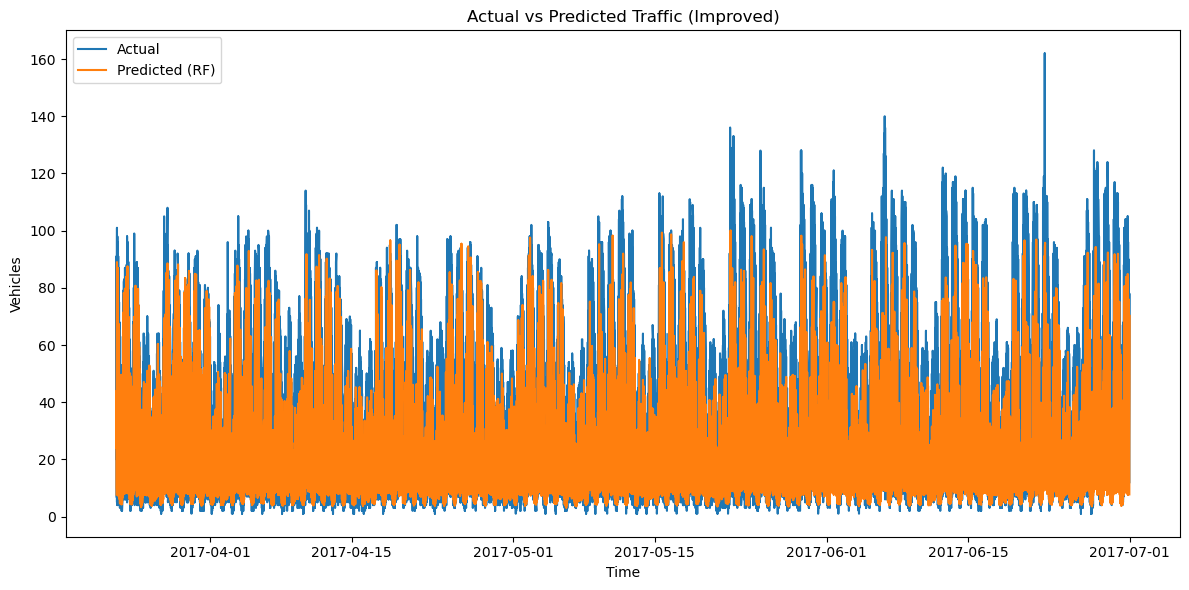

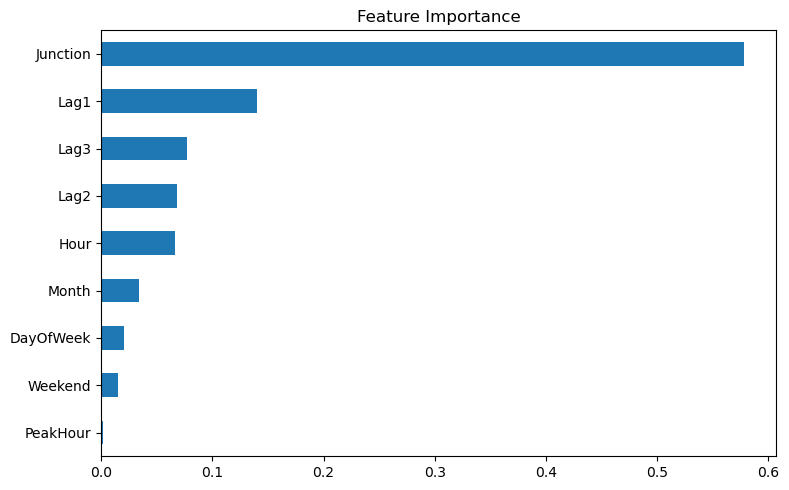


Predicted Traffic: 17.671056122091418


C:\Users\Tarun\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(


In [12]:
# ============================================
# 1. Import Libraries
# ============================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

# ============================================
# 2. Load Dataset
# ============================================
df = pd.read_csv("traffic.csv")

print("Dataset Shape:", df.shape)
print(df.head())

# ============================================
# 3. Data Preprocessing
# ============================================

df['DateTime'] = pd.to_datetime(df['DateTime'])
df = df.sort_values('DateTime')

print(df.isnull().sum())

# ============================================
# 4. Feature Engineering
# ============================================

df['Year'] = df['DateTime'].dt.year
df['Month'] = df['DateTime'].dt.month
df['Day'] = df['DateTime'].dt.day
df['Hour'] = df['DateTime'].dt.hour
df['DayOfWeek'] = df['DateTime'].dt.dayofweek

df['Weekend'] = df['DayOfWeek'].apply(lambda x: 1 if x >= 5 else 0)
df['PeakHour'] = df['Hour'].apply(lambda x: 1 if (7 <= x <= 10 or 17 <= x <= 20) else 0)

# 🔥 NEW: Lag Features (IMPORTANT)
df['Lag1'] = df['Vehicles'].shift(1)
df['Lag2'] = df['Vehicles'].shift(2)
df['Lag3'] = df['Vehicles'].shift(3)

df = df.dropna()

# ============================================
# 5. Visualization (Improved)
# ============================================

# Traffic over time
plt.figure(figsize=(12,6))
plt.plot(df['DateTime'], df['Vehicles'])
plt.title("Traffic Over Time")
plt.xlabel("Time")
plt.ylabel("Vehicles")
plt.tight_layout()
plt.show()

# Junction-wise traffic
for j in sorted(df['Junction'].unique()):
    temp = df[df['Junction'] == j]
    
    plt.figure(figsize=(12,6))
    plt.plot(temp['DateTime'], temp['Vehicles'])
    plt.title(f"Traffic at Junction {j}")
    plt.xlabel("Time")
    plt.ylabel("Vehicles")
    plt.tight_layout()
    plt.show()

# Hour vs Traffic
hourly = df.groupby('Hour')['Vehicles'].mean()
plt.figure(figsize=(10,5))
hourly.plot(kind='bar')
plt.title("Average Traffic per Hour")
plt.xlabel("Hour")
plt.ylabel("Vehicles")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# ============================================
# 6. Prepare Data
# ============================================

features = ['Hour', 'DayOfWeek', 'Month', 'Weekend', 'PeakHour',
            'Junction', 'Lag1', 'Lag2', 'Lag3']

X = df[features]
y = df['Vehicles']

split = int(len(df) * 0.8)

X_train = X[:split]
X_test = X[split:]
y_train = y[:split]
y_test = y[split:]

# ============================================
# 7. Models
# ============================================

# Linear Regression
lr = LinearRegression()
lr.fit(X_train, y_train)
lr_pred = lr.predict(X_test)

# Random Forest (Improved)
rf = RandomForestRegressor(
    n_estimators=200,
    max_depth=12,
    random_state=42
)

rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)

# ============================================
# 8. Evaluation
# ============================================

def evaluate(y_true, y_pred, name):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    
    print(f"\n{name} Performance:")
    print("MAE:", mae)
    print("RMSE:", rmse)

evaluate(y_test, lr_pred, "Linear Regression")
evaluate(y_test, rf_pred, "Random Forest")

# ============================================
# 9. Plot Predictions (FIXED GRAPH)
# ============================================

plt.figure(figsize=(12,6))

plt.plot(df['DateTime'][split:], y_test.values, label="Actual")
plt.plot(df['DateTime'][split:], rf_pred, label="Predicted (RF)")

plt.xticks(rotation=0)
plt.legend()
plt.title("Actual vs Predicted Traffic (Improved)")
plt.xlabel("Time")
plt.ylabel("Vehicles")
plt.tight_layout()
plt.show()

# ============================================
# 10. Feature Importance
# ============================================

importance = pd.Series(rf.feature_importances_, index=features)

plt.figure(figsize=(8,5))
importance.sort_values().plot(kind='barh')
plt.title("Feature Importance")
plt.tight_layout()
plt.show()

# ============================================
# 11. Future Prediction
# ============================================

# Example input
future = np.array([[9, 1, 3, 0, 1, 2, 50, 45, 48]])  
# (Lag values should be recent traffic values)

prediction = rf.predict(future)

print("\nPredicted Traffic:", prediction[0])